# 01 · Log QC and machine-learning gap fill

Runs the SubsurfiX pipeline on 60 public Kansas Geological Survey (KGS) wells: ingest, quality control (QC),
and gap fill of six logs (GR, RHOB, NPHI, DTC, RESD, PEF). Missing intervals are predicted with gradient-boosted
trees, LightGBM (Ke et al. 2017,
*LightGBM: A Highly Efficient Gradient Boosting Decision Tree*, NeurIPS).

Data: KGS digital LAS archive. Download with `scripts/fetch_open_data.sh`.

## Setup
Set `SX_EXAMPLE_PROJECT` to your KGS project folder (default `kgs_project/` next to this notebook).

In [1]:
import os
from pathlib import Path
import numpy as np, pandas as pd, pyarrow.parquet as pq
import matplotlib.pyplot as plt
%matplotlib inline
# SX_EXAMPLE_PROJECT: KGS project folder (las/, edges/, project.toml), see scripts/fetch_open_data.sh.
# SX_EXAMPLE_OUT: folder for figures and the small model files passed between notebooks.
PROJ = Path(os.environ.get("SX_EXAMPLE_PROJECT", "kgs_project")).resolve()
OUT = Path(os.environ.get("SX_EXAMPLE_OUT", "outputs")).resolve()
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110})
def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight")

## Run the pipeline
`Project.run()` reruns only the stages whose inputs changed.

In [2]:
import subsurfix as sx
p = sx.Project(PROJ / "project.toml")
p.run()
p.status().to_pandas()[["stage", "state"]]

,stage,state
0,ingest,up_to_date
1,qc,up_to_date
2,rough_align,up_to_date
3,normalize,up_to_date
4,neighbors,up_to_date
5,fill,up_to_date
6,correlate,up_to_date
7,subhorizons,up_to_date
8,refresh,up_to_date
9,export,up_to_date


## QC report
Samples removed by each QC rule, summed over wells.

In [3]:
rep = pd.read_csv(PROJ / "stages/qc/qc_report.csv")
cols = [c for c in rep.columns if c.startswith("n_")]
rep.groupby("log")[cols].sum()

,n_raw,n_out_of_bounds,n_tail,n_repeat,n_plateau,n_short_run,n_channel,n_bad_hole,n_implausible,n_low_density_unverified,n_closed_cal_rescued,n_qc
log,,,,,,,,,,,,
DTC,58626,0,43,0,1703,64,0,0,0,0,0,56816
GR,582741,0,1124,0,0,116,0,0,0,0,0,581501
NPHI,481730,0,297,0,195,238,0,0,0,0,0,481000
PEF,218195,43823,75,0,89,4035,0,43789,34,0,0,170173
RESD,582793,0,779,0,11163,6257,0,0,0,0,0,564594
RHOB,482603,199132,291,0,33,6560,0,199128,4,0,9061,276587


## Fill provenance
Share of each final log that is measured, predicted by the model, copied from a neighbor, or left unfilled.

,gr,rhob,nphi,dtc,resd,pef
copy/other,0.002,0.001,0.00,0.041,0.005,0.024
measured,0.979,0.453,0.81,0.096,0.950,0.287
model,0.019,0.546,0.19,0.863,0.044,0.689
unfilled,0.000,0.000,0.00,0.000,0.000,0.000


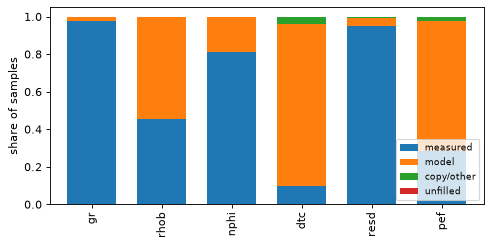

In [4]:
fin = pq.read_table(PROJ / "export/logs_final.parquet").to_pandas()
logs = ["gr", "rhob", "nphi", "dtc", "resd", "pef"]
lab = lambda c: "measured" if c == 0 else "model" if c == 1 else "unfilled" if c == 9 else "copy/other"
prov = pd.DataFrame({l: fin[f"{l}_prov"].map(lab).value_counts(normalize=True) for l in logs}).fillna(0)
fig, ax = plt.subplots(figsize=(7, 3.2))
prov.T.reindex(columns=["measured", "model", "copy/other", "unfilled"], fill_value=0).plot.bar(stacked=True, ax=ax, width=0.7)
ax.set_ylabel("share of samples"); ax.legend(fontsize=8, loc="lower right")
save(fig, "01_fill_provenance.png")
prov.round(3)

## One well: raw, after QC, filled
Grey is the raw log, black what QC kept, red the filled samples.

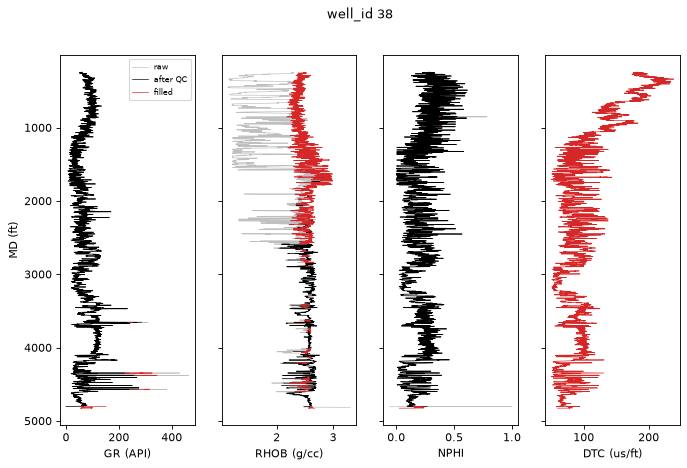

In [5]:
raw = pq.read_table(PROJ / "stages/ingest/logs_raw.parquet").to_pandas()
qc = pq.read_table(PROJ / "stages/qc/logs_qc.parquet").to_pandas()
share = fin.groupby("well_id").rhob_prov.apply(lambda s: (s == 1).mean()).sort_values()
wid = share.index[len(share) // 2]
cols = [("gr_api", "GR (API)"), ("rhob_gcc", "RHOB (g/cc)"), ("nphi_frac", "NPHI"), ("dtc_usft", "DTC (us/ft)")]
r, q, f = (d[d.well_id == wid] for d in (raw, qc, fin))
fig, axs = plt.subplots(1, 4, figsize=(10, 6), sharey=True)
for ax, (c, lab) in zip(axs, cols):
    ax.plot(r[c], r.md_ft, color="0.75", lw=0.6, label="raw")
    ax.plot(q[c], q.md_ft, color="k", lw=0.6, label="after QC")
    ax.plot(f[c].where(f[f"{c.split('_')[0]}_prov"] != 0), f.md_ft, color="tab:red", lw=0.6, label="filled")
    ax.set_xlabel(lab)
axs[0].invert_yaxis(); axs[0].set_ylabel("MD (ft)"); axs[0].legend(fontsize=7)
fig.suptitle(f"well_id {wid}"); save(fig, "01_well_tracks.png")